<a href="https://colab.research.google.com/github/michaeladenrele18/svm_mini_project/blob/Vince%2FKernel/polynomial_kernel_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install cvxopt

     POLYNOMIAL SVM RESULTS (COLAB)       
Polynomial Degree (d) : 2
Offset Constant (c)   : 1.0
Support Vectors Found : 5 / 160
Fitted Bias (b)       : 1.6736
Test Accuracy         : 100.00%


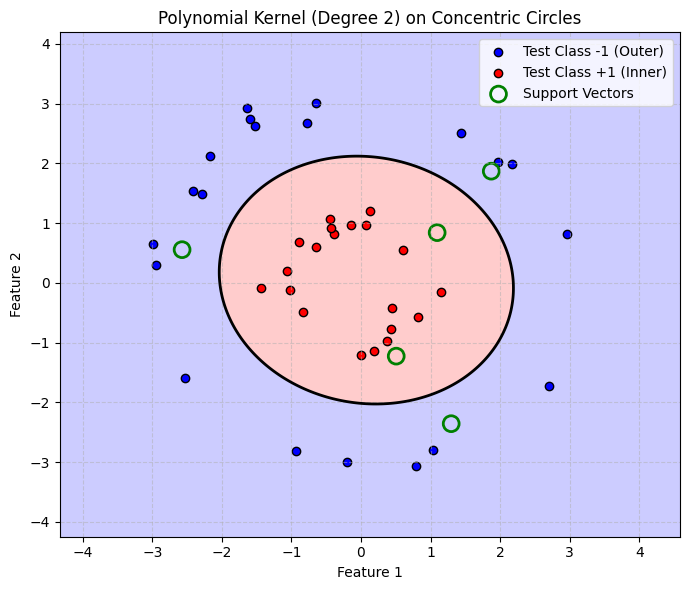

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cvxopt import matrix, solvers

#
# 1. POLYNOMIAL KERNEL IMPLEMENTATION

def polynomial_kernel(X1, X2, degree=2, c=1.0):
    """
    Computes the standard textbook polynomial kernel:
        K(x, z) = (x^T z + c)^d
    """
    X1 = np.asarray(X1, dtype=float)
    X2 = np.asarray(X2, dtype=float)
    return (X1 @ X2.T + c) ** degree



# 2. DUAL SVM SOLVER (CVXOPT)

def train_poly_svm(X, y, C=1.0, degree=2, c=1.0, tol=1e-5):
    """
    Solves the dual soft-margin SVM quadratic program via CVXOPT:
        min  0.5 * alpha^T P alpha - sum(alpha)
        s.t. 0 <= alpha_i <= C,  sum(alpha_i * y_i) = 0
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    N = X.shape[0]

    # Compute Gram matrix using polynomial kernel
    K = polynomial_kernel(X, X, degree=degree, c=c)
    P = np.outer(y, y) * K
    q = -np.ones(N)

    # Box constraints: 0 <= alpha_i <= C
    I = np.eye(N)
    G = np.vstack((-I, I))
    h = np.hstack((np.zeros(N), C * np.ones(N)))

    # Equality constraint: sum(alpha_i * y_i) = 0
    A = y.reshape(1, -1)
    b = np.array([0.0])

    # Convert to CVXOPT matrices and solve
    solvers.options["show_progress"] = False
    solution = solvers.qp(
        matrix(P, tc="d"),
        matrix(q, tc="d"),
        matrix(G, tc="d"),
        matrix(h, tc="d"),
        matrix(A, tc="d"),
        matrix(b, tc="d"),
    )
    alpha = np.array(solution["x"]).flatten()

    # Identify support vectors
    sv_mask = alpha > tol
    sv_X = X[sv_mask]
    sv_y = y[sv_mask]
    sv_alpha = alpha[sv_mask]

    # Compute bias intercept b using free margin vectors (0 < alpha < C)
    free = (alpha > tol) & (alpha < C - tol)
    if not np.any(free):
        free = sv_mask

    decision_no_bias = K @ (alpha * y)
    bias = float(np.mean(y[free] - decision_no_bias[free]))

    return {
        "sv_X": sv_X,
        "sv_y": sv_y,
        "sv_alpha": sv_alpha,
        "bias": bias,
        "degree": degree,
        "c": c,
        "C": C,
    }


def predict(X, model):
    """Evaluates decision score: f(x) = sum(alpha_i * y_i * K(x_i, x)) + b"""
    X = np.asarray(X, dtype=float)
    K_test = polynomial_kernel(
        X, model["sv_X"], degree=model["degree"], c=model["c"]
    )
    scores = K_test @ (model["sv_alpha"] * model["sv_y"]) + model["bias"]
    return np.where(scores >= 0.0, 1.0, -1.0)



# 3. RUN ON NONLINEAR CIRCLES DATASET

train_df = pd.read_csv("/nonlinear_circles_train.csv")
test_df = pd.read_csv("nonlinear_circles_test.csv")

X_train = train_df[["Feature1", "Feature2"]].values
y_train = train_df["Label"].values

X_test = test_df[["Feature1", "Feature2"]].values
y_test = test_df["Label"].values

# Train degree-2 polynomial SVM
model = train_poly_svm(X_train, y_train, C=1.0, degree=2, c=1.0)
y_pred = predict(X_test, model)

accuracy = np.mean(y_pred == y_test) * 100
n_sv = len(model["sv_X"])


print("     POLYNOMIAL SVM RESULTS (COLAB)       ")

print(f"Polynomial Degree (d) : {model['degree']}")
print(f"Offset Constant (c)   : {model['c']}")
print(f"Support Vectors Found : {n_sv} / {len(X_train)}")
print(f"Fitted Bias (b)       : {model['bias']:.4f}")
print(f"Test Accuracy         : {accuracy:.2f}%")



# 4. DECISION BOUNDARY PLOT (Rendered Inline)

plt.figure(figsize=(7, 6))

x1_min, x1_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
x2_min, x2_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 250), np.linspace(x2_min, x2_max, 250)
)
grid_points = np.c_[xx.ravel(), yy.ravel()]

K_grid = polynomial_kernel(
    grid_points, model["sv_X"], degree=model["degree"], c=model["c"]
)
Z = (
    K_grid @ (model["sv_alpha"] * model["sv_y"]) + model["bias"]
).reshape(xx.shape)

plt.contourf(
    xx, yy, Z, levels=[-100, 0, 100], alpha=0.2, colors=["blue", "red"]
)
plt.contour(xx, yy, Z, levels=[0], colors="black", linewidths=2)

plt.scatter(
    X_test[y_test == -1, 0],
    X_test[y_test == -1, 1],
    c="blue",
    edgecolors="k",
    label="Test Class -1 (Outer)",
)
plt.scatter(
    X_test[y_test == 1, 0],
    X_test[y_test == 1, 1],
    c="red",
    edgecolors="k",
    label="Test Class +1 (Inner)",
)
plt.scatter(
    model["sv_X"][:, 0],
    model["sv_X"][:, 1],
    s=130,
    facecolors="none",
    edgecolors="green",
    linewidths=2,
    label="Support Vectors",
)

plt.title("Polynomial Kernel (Degree 2) on Concentric Circles", fontsize=12)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
#  Load Breast Cancer Data
bc_train = pd.read_csv("/breast_cancer_train.csv")
bc_test = pd.read_csv("/breast_cancer_test.csv")

# Extract features (all columns except 'Label')
feature_cols = [c for c in bc_train.columns if c != "Label"]
X_tr_bc = bc_train[feature_cols].values
y_tr_bc = bc_train["Label"].values.astype(float)

X_te_bc = bc_test[feature_cols].values
y_te_bc = bc_test["Label"].values.astype(float)

# Linear SVM Baseline on Breast Cancer (degree=1, c=0.0)
model_bc_lin = train_poly_svm(X_tr_bc, y_tr_bc, C=1.0, degree=1, c=0.0)
preds_bc_lin = predict(X_te_bc, model_bc_lin)
acc_bc_lin = np.mean(preds_bc_lin == y_te_bc) * 100

# Polynomial SVM on Breast Cancer (degree=2, c=1.0)

model_bc_poly = train_poly_svm(X_tr_bc, y_tr_bc, C=1.0, degree=2, c=1.0)
preds_bc_poly = predict(X_te_bc, model_bc_poly)
acc_bc_poly = np.mean(preds_bc_poly == y_te_bc) * 100

print(f"Breast Cancer - Linear Baseline Acc : {acc_bc_lin:.2f}% (SVs: {len(model_bc_lin['sv_X'])})")
print(f"Breast Cancer - Polynomial (d=2) Acc: {acc_bc_poly:.2f}% (SVs: {len(model_bc_poly['sv_X'])})")

Breast Cancer - Linear Baseline Acc : 95.58% (SVs: 35)
Breast Cancer - Polynomial (d=2) Acc: 95.58% (SVs: 62)
